# 32 — Figuras de resultados para el video

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [`24-jss-figuras-pre-informe.ipynb`](24-jss-figuras-pre-informe.ipynb) ·
[`31-jss-resultados-finales.ipynb`](31-jss-resultados-finales.ipynb)

---

## Qué hace este notebook

Genera seis figuras para el video de resultados preliminares y las exporta como PNG a
[`docs/entregables/figuras/`](../docs/entregables/figuras/) con el prefijo `resultados-`. Siguen la guía de
la clase 4 de AFG2: el título es la conclusión, las barras parten de cero, el valor clave va en color y el
resto en gris, cada barra lleva su valor escrito y las letras son legibles al tamaño de un video.

**No se calcula ninguna cifra nueva.** Los valores se leen de las tablas congeladas
`reports/tables/final-*` (las del notebook 31) y, para el acuerdo entre anotadores de OE1, de la misma
función del notebook 24. La selección de cada valor está en `afg.experiments.video_results` y el dibujo en
`afg.eda.figures`, ambos con tests. No se llama a ningún modelo y no se necesita el corpus.

> **Aviso de alcance (ADR 0005).** Solo se muestran cifras agregadas; no se cita texto de transcripciones,
> respuestas ni decisiones.

In [1]:
import warnings

import pandas as pd
from IPython.display import Markdown, display

from afg.annotation.pooled import pooled_agreement_report
from afg.annotation.workspace import load_annotation_plan
from afg.eda.figures import (
    plot_grouped_bars,
    plot_hbars,
    plot_kappa_bands,
    save_figure,
    video_style,
)
from afg.eda.tables import format_thousands as es
from afg.experiments.video_results import (
    CONDITION_LABELS,
    STAGE_LABELS,
    STRATUM_LABELS,
    answer_latency,
    correctness_by_type,
    failure_causes,
    headline_point,
    phase2_kappas,
    total_correctness,
)
from afg.shared.paths import PROJECT_ROOT

# Cohen's kappa is undefined (NaN) when both annotators use one label; scikit-learn warns about it.
warnings.filterwarnings("ignore", module="sklearn")

TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
FIGURES_DIR = PROJECT_ROOT / "docs" / "entregables" / "figuras"
CELLS = pd.read_csv(TABLES_DIR / "final-b-cells.csv")
HEADLINE = pd.read_csv(TABLES_DIR / "final-a-headline.csv")
OE4 = pd.read_csv(TABLES_DIR / "final-oe4-stages.csv")
COST = pd.read_csv(TABLES_DIR / "final-cost-latency.csv")
EXPORTED = []
DRAWN = {}  # figure name -> values of its bars, read back from the figure itself


def pct(value):
    return f"{es(value * 100, 0)} %"


def export(fig, name):
    """Save the figure, remember the values of its bars and show it."""
    path = save_figure(fig, FIGURES_DIR / f"resultados-{name}.png")
    DRAWN[name] = [float(v) for c in fig.axes[0].containers for v in c.datavalues]
    EXPORTED.append(path)
    display(fig)

---

# 1. OE1: acuerdo entre las dos personas que anotaron

**Qué se hace y por qué.** La referencia de OE1 (qué decisiones están enlazadas y cómo) la anotaron dos
personas por separado. El kappa de Cohen mide cuánto coinciden descontando el azar. Se dibujan los dos ejes
con kappa definido, existencia del enlace y tipo de enlace, sobre las bandas de lectura de Landis y Koch.
Se usa solo el alcance de la Fase 2, que es la cifra reportable (igual que en el notebook 24).

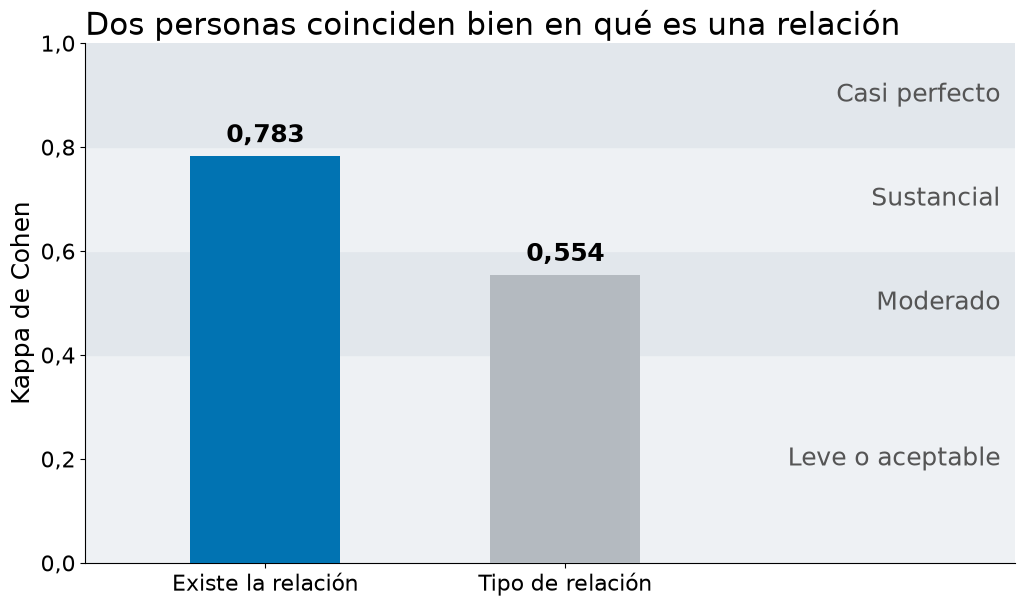


**Lectura.** El acuerdo sobre si dos decisiones están enlazadas es sustancial (kappa
0,783); sobre el tipo de enlace es moderado (kappa
0,554). La referencia es confiable para decidir si hay una
relación y menos para clasificarla, y eso fija la cota con la que debe leerse la
exactitud de tipo de cualquier sistema.

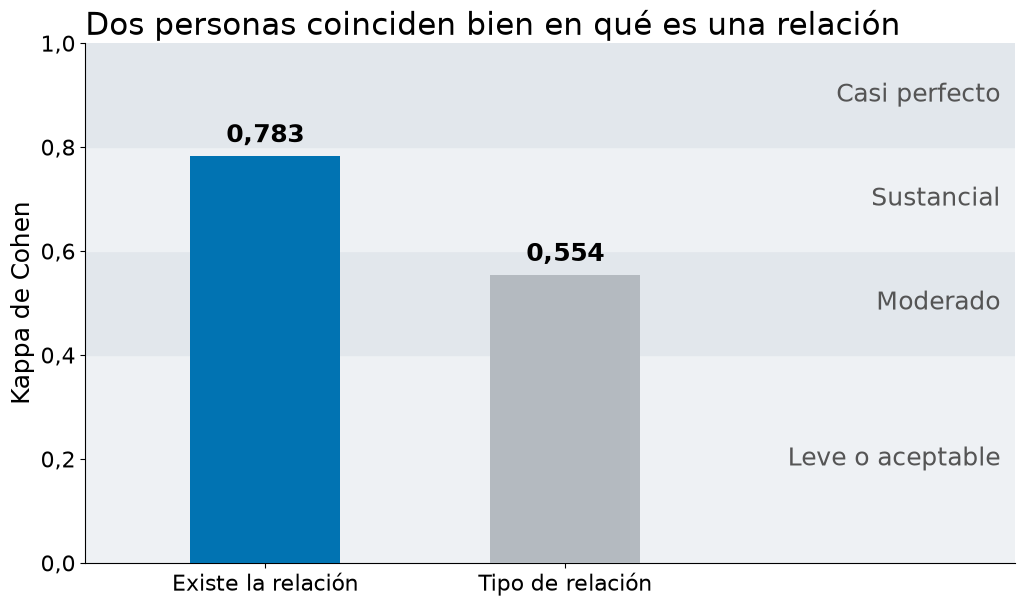

In [2]:
KAPPA = phase2_kappas(pooled_agreement_report(load_annotation_plan()))
KAPPA_LABELS = {"existence": "Existe la relación", "type": "Tipo de relación"}
with video_style():
    fig = plot_kappa_bands(
        {KAPPA_LABELS[axis]: value for axis, value in KAPPA.items()},
        highlight={KAPPA_LABELS["existence"]},
        title="Dos personas coinciden bien en qué es una relación",
    )
    export(fig, "oe1-kappa")
display(
    Markdown(
        f"""
**Lectura.** El acuerdo sobre si dos decisiones están enlazadas es sustancial (kappa
{es(KAPPA["existence"], 3)}); sobre el tipo de enlace es moderado (kappa
{es(KAPPA["type"], 3)}). La referencia es confiable para decidir si hay una
relación y menos para clasificarla, y eso fija la cota con la que debe leerse la
exactitud de tipo de cualquier sistema."""
    )
)

---

# 2. OE3: respuestas correctas por condición

**Qué se hace y por qué.** En el experimento B el mismo generador responde las mismas 99 preguntas con
cuatro contextos distintos. Se dibuja la proporción de respuestas correctas de cada uno y se destacan las
dos condiciones con base de decisiones, que son las que compara la hipótesis; las otras quedan en gris.

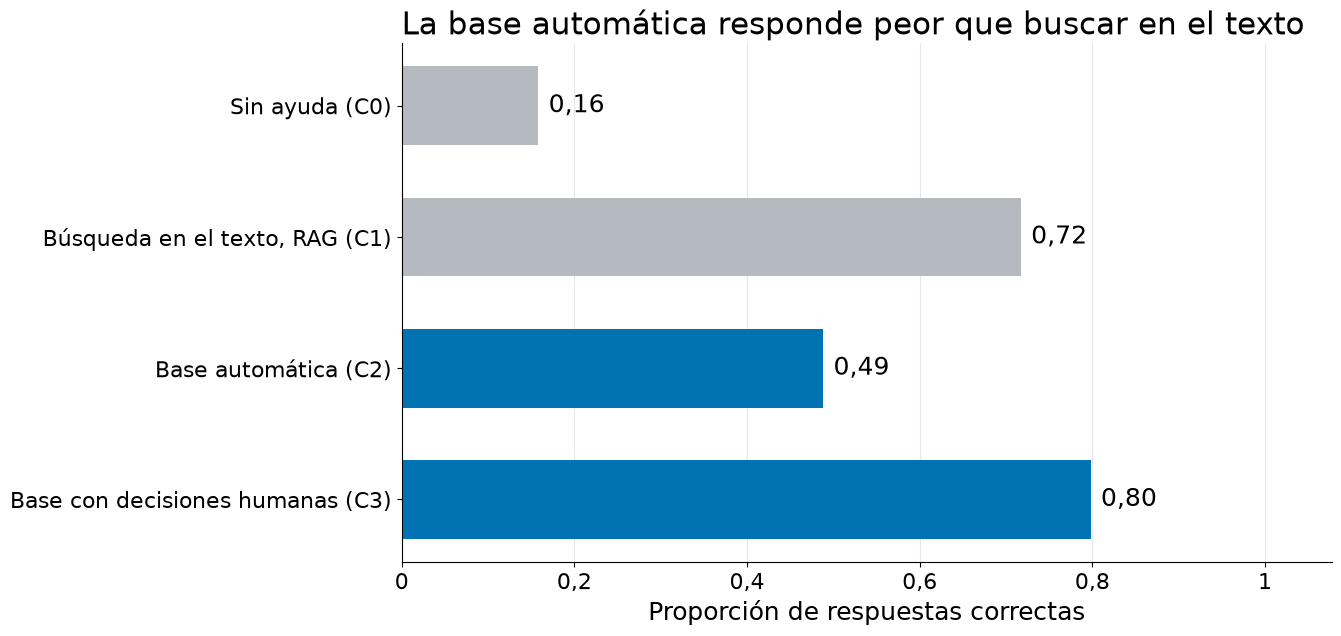


**Lectura.** Sin ayuda el generador acierta 16 % de las preguntas; buscando en
el texto, 72 %. La base construida automáticamente queda en
49 %, por debajo de la búsqueda en el texto, mientras que la base
con decisiones humanas llega a 80 %. La diferencia entre C2 y C3
señala que el cuello de botella está en construir la base y no en usarla.

In [3]:
TOTAL = total_correctness(CELLS)
with video_style():
    fig = plot_hbars(
        {CONDITION_LABELS[c]: v for c, v in TOTAL.items()},
        annotations=[es(v, 2) for v in TOTAL.values()],
        xlabel="Proporción de respuestas correctas",
        title="La base automática responde peor que buscar en el texto",
        highlight={CONDITION_LABELS["C2"], CONDITION_LABELS["C3"]},
    )
    export(fig, "oe3-total")
display(
    Markdown(
        f"""
**Lectura.** Sin ayuda el generador acierta {pct(TOTAL["C0"])} de las preguntas; buscando en
el texto, {pct(TOTAL["C1"])}. La base construida automáticamente queda en
{pct(TOTAL["C2"])}, por debajo de la búsqueda en el texto, mientras que la base
con decisiones humanas llega a {pct(TOTAL["C3"])}. La diferencia entre C2 y C3
señala que el cuello de botella está en construir la base y no en usarla."""
    )
)

---

# 3. OE3: respuestas correctas por tipo de pregunta

**Qué se hace y por qué.** Se separan las preguntas por lo que piden: un hecho puntual, el estado vigente
de una decisión o su evolución a lo largo de varias reuniones. Se comparan las tres condiciones con texto
o base. Se deja fuera el cuarto tipo (preguntas sin respuesta en el corpus) porque abstenerse cuenta como
acierto e infla a las condiciones que más se abstienen.

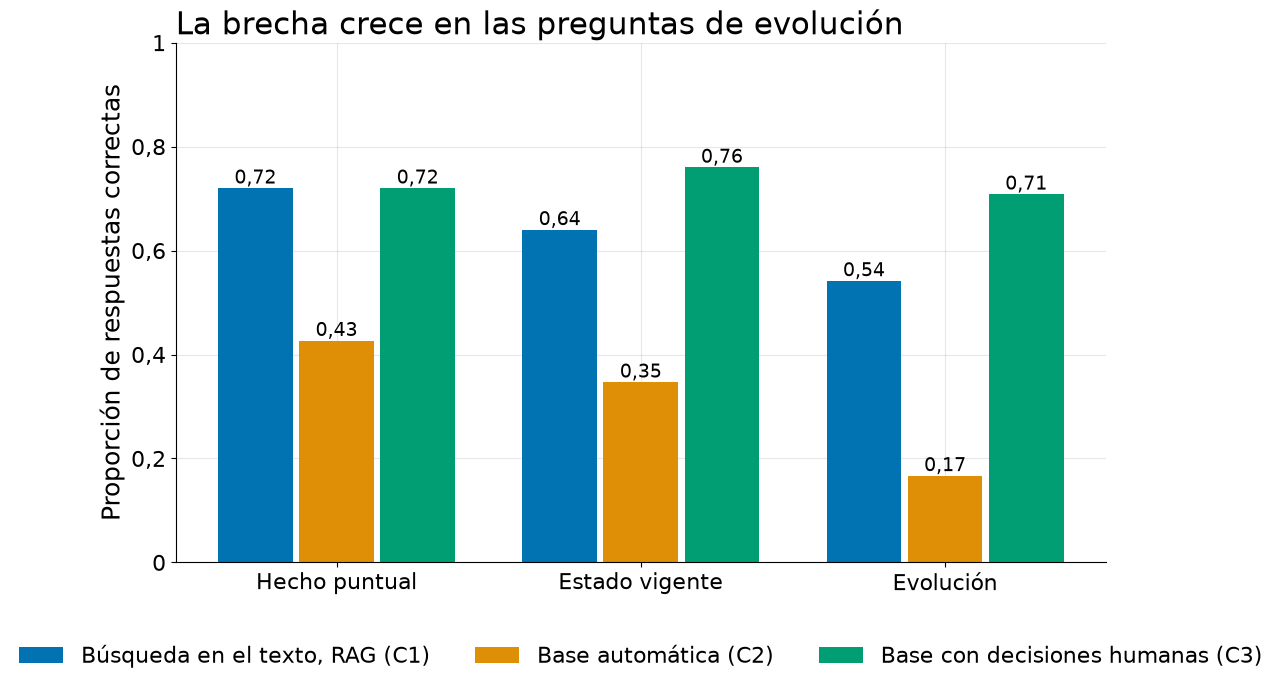


**Lectura.** La ventaja de buscar en el texto sobre la base automática pasa de
0,29 en los hechos puntuales a 0,29 en el estado vigente y
0,38 en la evolución, que es donde la base debía ayudar. La base con
decisiones humanas se mantiene entre 0,71 y
0,76 en los tres tipos.

In [4]:
BY_TYPE = correctness_by_type(CELLS)
with video_style():
    fig = plot_grouped_bars(
        list(STRATUM_LABELS.values()),
        {CONDITION_LABELS[c]: values for c, values in BY_TYPE.items()},
        ylabel="Proporción de respuestas correctas",
        title="La brecha crece en las preguntas de evolución",
        ylim=(0, 1),
        decimals=2,
    )
    export(fig, "oe3-por-tipo")
gap = [c1 - c2 for c1, c2 in zip(BY_TYPE["C1"], BY_TYPE["C2"], strict=True)]
display(
    Markdown(
        f"""
**Lectura.** La ventaja de buscar en el texto sobre la base automática pasa de
{es(gap[0], 2)} en los hechos puntuales a {es(gap[1], 2)} en el estado vigente y
{es(gap[2], 2)} en la evolución, que es donde la base debía ayudar. La base con
decisiones humanas se mantiene entre {es(min(BY_TYPE["C3"]), 2)} y
{es(max(BY_TYPE["C3"]), 2)} en los tres tipos."""
    )
)

---

# 4. OE2: cuántas decisiones encuentra la extracción

**Qué se hace y por qué.** Se compara lo que el sistema extrae con las decisiones de la referencia humana
en el umbral principal de similitud (τ = 0,70). La cobertura (recall) se traduce a «de cada 100 decisiones
humanas, cuántas encuentra»; la precisión y el F1 se escriben en el subtítulo.

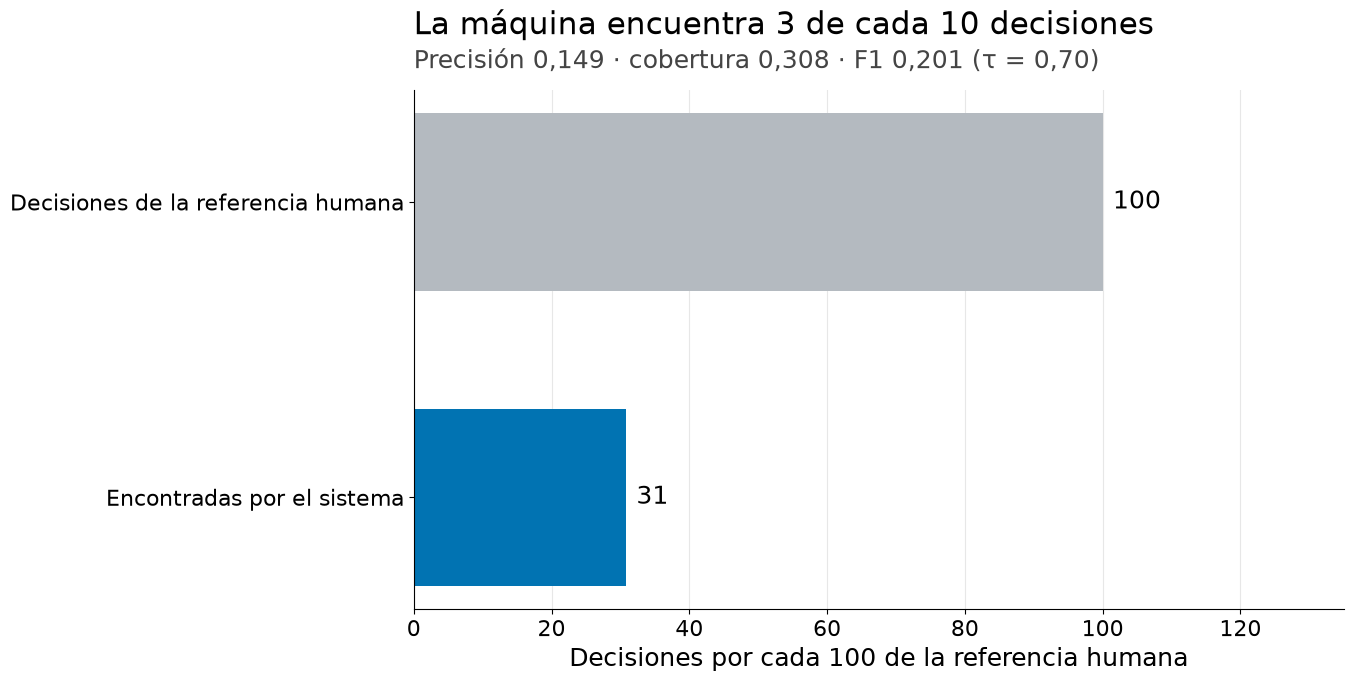


**Lectura.** El sistema encuentra 31 de cada 100 decisiones humanas (cobertura
0,308). Además, solo 15 de
cada 100 decisiones que propone coinciden con la referencia (precisión
0,149), de modo que el F1 es 0,201. Se
trata de una extracción que deja pasar la mayoría de las decisiones y mezcla las
acertadas con muchas propuestas sobrantes.

In [5]:
POINT = headline_point(HEADLINE, tau=0.7)
FOUND = POINT["recall"] * 100
with video_style():
    fig = plot_hbars(
        {"Decisiones de la referencia humana": 100.0, "Encontradas por el sistema": FOUND},
        annotations=["100", es(FOUND, 0)],
        xlabel="Decisiones por cada 100 de la referencia humana",
        title="La máquina encuentra 3 de cada 10 decisiones",
        subtitle=(
            f"Precisión {es(POINT['precision'], 3)} · cobertura {es(POINT['recall'], 3)}"
            f" · F1 {es(POINT['f1'], 3)} (τ = 0,70)"
        ),
        highlight={"Encontradas por el sistema"},
    )
    export(fig, "oe2-embudo")
display(
    Markdown(
        f"""
**Lectura.** El sistema encuentra {es(FOUND, 0)} de cada 100 decisiones humanas (cobertura
{es(POINT["recall"], 3)}). Además, solo {es(POINT["precision"] * 100, 0)} de
cada 100 decisiones que propone coinciden con la referencia (precisión
{es(POINT["precision"], 3)}), de modo que el F1 es {es(POINT["f1"], 3)}. Se
trata de una extracción que deja pasar la mayoría de las decisiones y mezcla las
acertadas con muchas propuestas sobrantes."""
    )
)

---

# 5. OE4: dónde fallan las respuestas de la base automática

**Qué se hace y por qué.** Cada respuesta incorrecta de la base automática se clasifica según la etapa en
que se originó el error: al extraer las decisiones, al recuperar las relevantes o al redactar la respuesta.
Se cuentan los casos de las tres etapas sobre el total de fallas y se destaca la mayor.

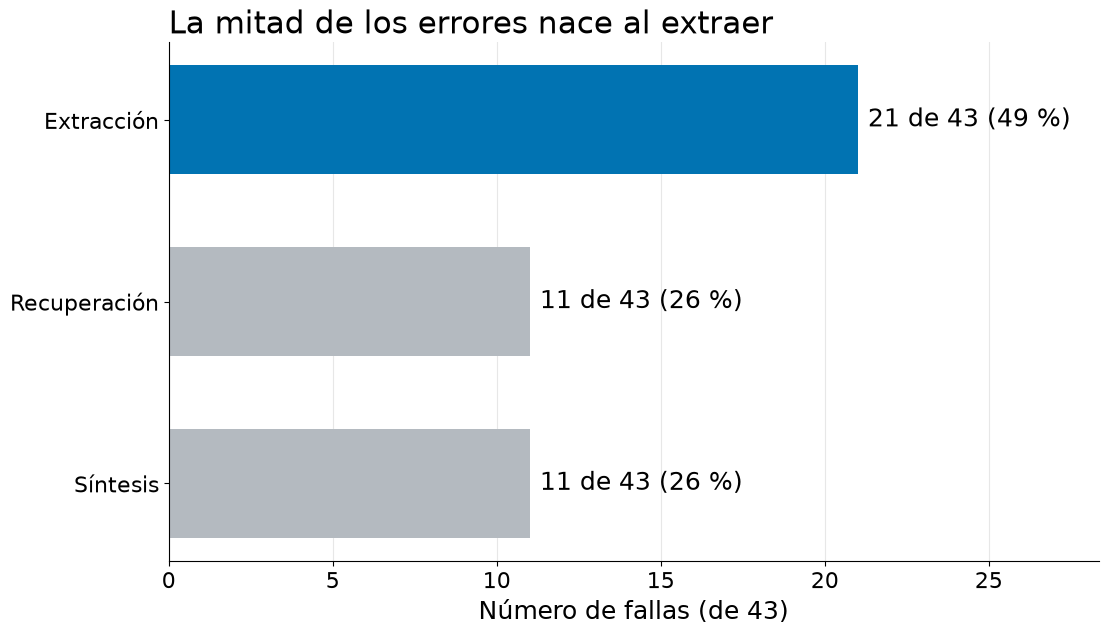


**Lectura.** De las 43 respuestas incorrectas, 21 se originan
al extraer las decisiones (49 %),
11 al recuperarlas y 11 al redactar la
respuesta. Mejorar la extracción es, por lo tanto, la palanca más grande para
cerrar la brecha con la búsqueda en el texto.

In [6]:
CAUSES, N_FAILURES = failure_causes(OE4)
with video_style():
    fig = plot_hbars(
        {STAGE_LABELS[s]: n for s, n in CAUSES.items()},
        annotations=[f"{n} de {N_FAILURES} ({pct(n / N_FAILURES)})" for n in CAUSES.values()],
        xlabel=f"Número de fallas (de {N_FAILURES})",
        title="La mitad de los errores nace al extraer",
        highlight={STAGE_LABELS["extraccion"]},
    )
    export(fig, "oe4-causas")
display(
    Markdown(
        f"""
**Lectura.** De las {N_FAILURES} respuestas incorrectas, {CAUSES["extraccion"]} se originan
al extraer las decisiones ({pct(CAUSES["extraccion"] / N_FAILURES)}),
{CAUSES["recuperacion"]} al recuperarlas y {CAUSES["sintesis"]} al redactar la
respuesta. Mejorar la extracción es, por lo tanto, la palanca más grande para
cerrar la brecha con la búsqueda en el texto."""
    )
)

---

# 6. Costo: tiempo de respuesta por consulta

**Qué se hace y por qué.** Además de acertar menos, importa cuánto tarda cada condición en responder una
consulta. Se dibuja el promedio de segundos por consulta del generador y se destacan las dos condiciones
que se comparan en la hipótesis de costo: buscar en el texto y la base automática.

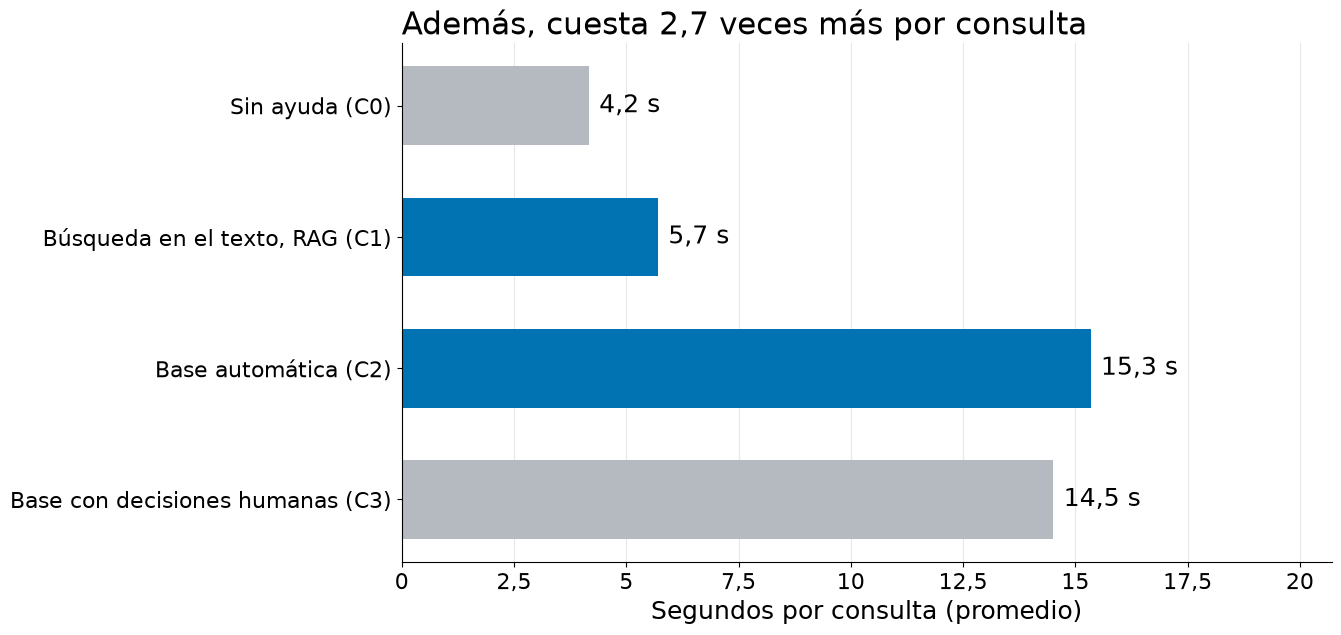


**Lectura.** Responder con la base automática toma 15,3 s por consulta
frente a 5,7 s al buscar en el texto, es decir 2,7
veces más. Compilar la base además tiene un costo inicial, de modo que no existe
un punto de equilibrio en que resulte más barata (tabla `final-break-even`).

In [7]:
LATENCY = answer_latency(COST)
RATIO = LATENCY["C2"] / LATENCY["C1"]
with video_style():
    fig = plot_hbars(
        {CONDITION_LABELS[c]: v for c, v in LATENCY.items()},
        annotations=[f"{es(v, 1)} s" for v in LATENCY.values()],
        xlabel="Segundos por consulta (promedio)",
        title=f"Además, cuesta {es(RATIO, 1)} veces más por consulta",
        highlight={CONDITION_LABELS["C1"], CONDITION_LABELS["C2"]},
    )
    export(fig, "costo-latencia")
display(
    Markdown(
        f"""
**Lectura.** Responder con la base automática toma {es(LATENCY["C2"], 1)} s por consulta
frente a {es(LATENCY["C1"], 1)} s al buscar en el texto, es decir {es(RATIO, 1)}
veces más. Compilar la base además tiene un costo inicial, de modo que no existe
un punto de equilibrio en que resulte más barata (tabla `final-break-even`)."""
    )
)

---

# 7. Comprobación contra las tablas congeladas

Se comprueba que los valores dibujados, leídos de cada figura, coinciden con las cifras de las tablas
finales (con el redondeo de la cifra mostrada).

In [8]:
ACCEPTED = {
    "oe1-kappa": [0.783, 0.554],
    "oe3-total": [0.16, 0.72, 0.49, 0.80],
    "oe3-por-tipo": [0.72, 0.64, 0.54, 0.43, 0.35, 0.17, 0.72, 0.76, 0.71],
    "oe2-embudo": [100.0, 30.8],
    "oe4-causas": [21, 11, 11],
    "costo-latencia": [4.2, 5.7, 15.3, 14.5],
}
# Grouped bars come one container per condition (C1, C2, C3), three question types each.
digits = {"oe1-kappa": 3, "oe2-embudo": 1, "oe4-causas": 0, "costo-latencia": 1}
for name, expected in ACCEPTED.items():
    drawn = [round(v, digits.get(name, 2)) for v in DRAWN[name]]
    assert drawn == [round(v, digits.get(name, 2)) for v in expected], (name, drawn, expected)
assert round(RATIO, 1) == 2.7 and N_FAILURES == 43
print("Todas las cifras dibujadas coinciden con las tablas congeladas.")
for path in EXPORTED:
    print(path.relative_to(PROJECT_ROOT))

Todas las cifras dibujadas coinciden con las tablas congeladas.
docs/entregables/figuras/resultados-oe1-kappa.png
docs/entregables/figuras/resultados-oe3-total.png
docs/entregables/figuras/resultados-oe3-por-tipo.png
docs/entregables/figuras/resultados-oe2-embudo.png
docs/entregables/figuras/resultados-oe4-causas.png
docs/entregables/figuras/resultados-costo-latencia.png
